In [12]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [13]:
# Q1a) hyperparameters
num_words = 10000    # TODO (Q1a): keep the 10000 most frequent words
maxlen    = 200    # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=200)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=200)   # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)   # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


In [14]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


In [15]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))   # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation='sigmoid'))   # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Q3a) compile for binary classification
model.compile(optimizer ='adam', loss ='binary_crossentropy',
                metrics =['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,          # TODO (Q3b): 5
                    batch_size=64)      # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7833 - loss: 0.4531 - val_accuracy: 0.8534 - val_loss: 0.3536
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8981 - loss: 0.2604 - val_accuracy: 0.8552 - val_loss: 0.3485
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9264 - loss: 0.1973 - val_accuracy: 0.8704 - val_loss: 0.3349
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9506 - loss: 0.1379 - val_accuracy: 0.8546 - val_loss: 0.3553
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9615 - loss: 0.1070 - val_accuracy: 0.8648 - val_loss: 0.4543


782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8534 - loss: 0.4730
Test accuracy: 85.34%


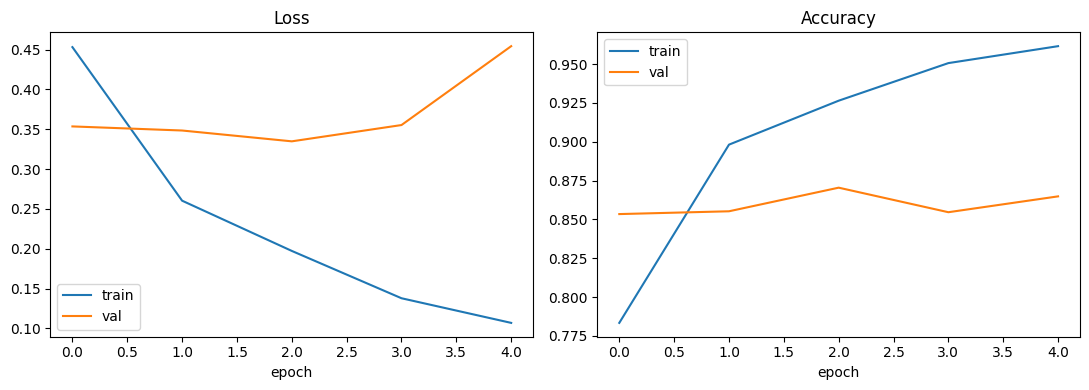

In [21]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

In [22]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"   # TODO (Q5): 0.5

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time



1. **Yes, validation loss starts rising** (after epoch 2, as seen in the Loss plot).

2. This indicates **overfitting**, where the model begins to memorize the training data rather than generalizing well to unseen data.

3. **`Dropout(0.5)`** randomly deactivates 50% of the neurons during each training step.

4. This prevents neurons from co-adapting too much, forcing the network to learn more robust, redundant features.

5. Ultimately, it **reduces overfitting** and helps the model generalize better to the validation/test datasets.